# Лабораторная работа №3: оптимизация гиперпараметров

**Задача:** регрессия на Wine Quality (из лабораторной №1), целевая переменная `quality`. **Модель:** `GradientBoostingRegressor`. **Метрика:** RMSE (основная), MAE (дополнительная).

**План:** baseline → выбор гиперпараметров → кросс-валидация → Grid Search → Random Search → влияние гиперпараметров (недообучение / норма / переобучение) → финальная оценка на test → устойчивость по folds.

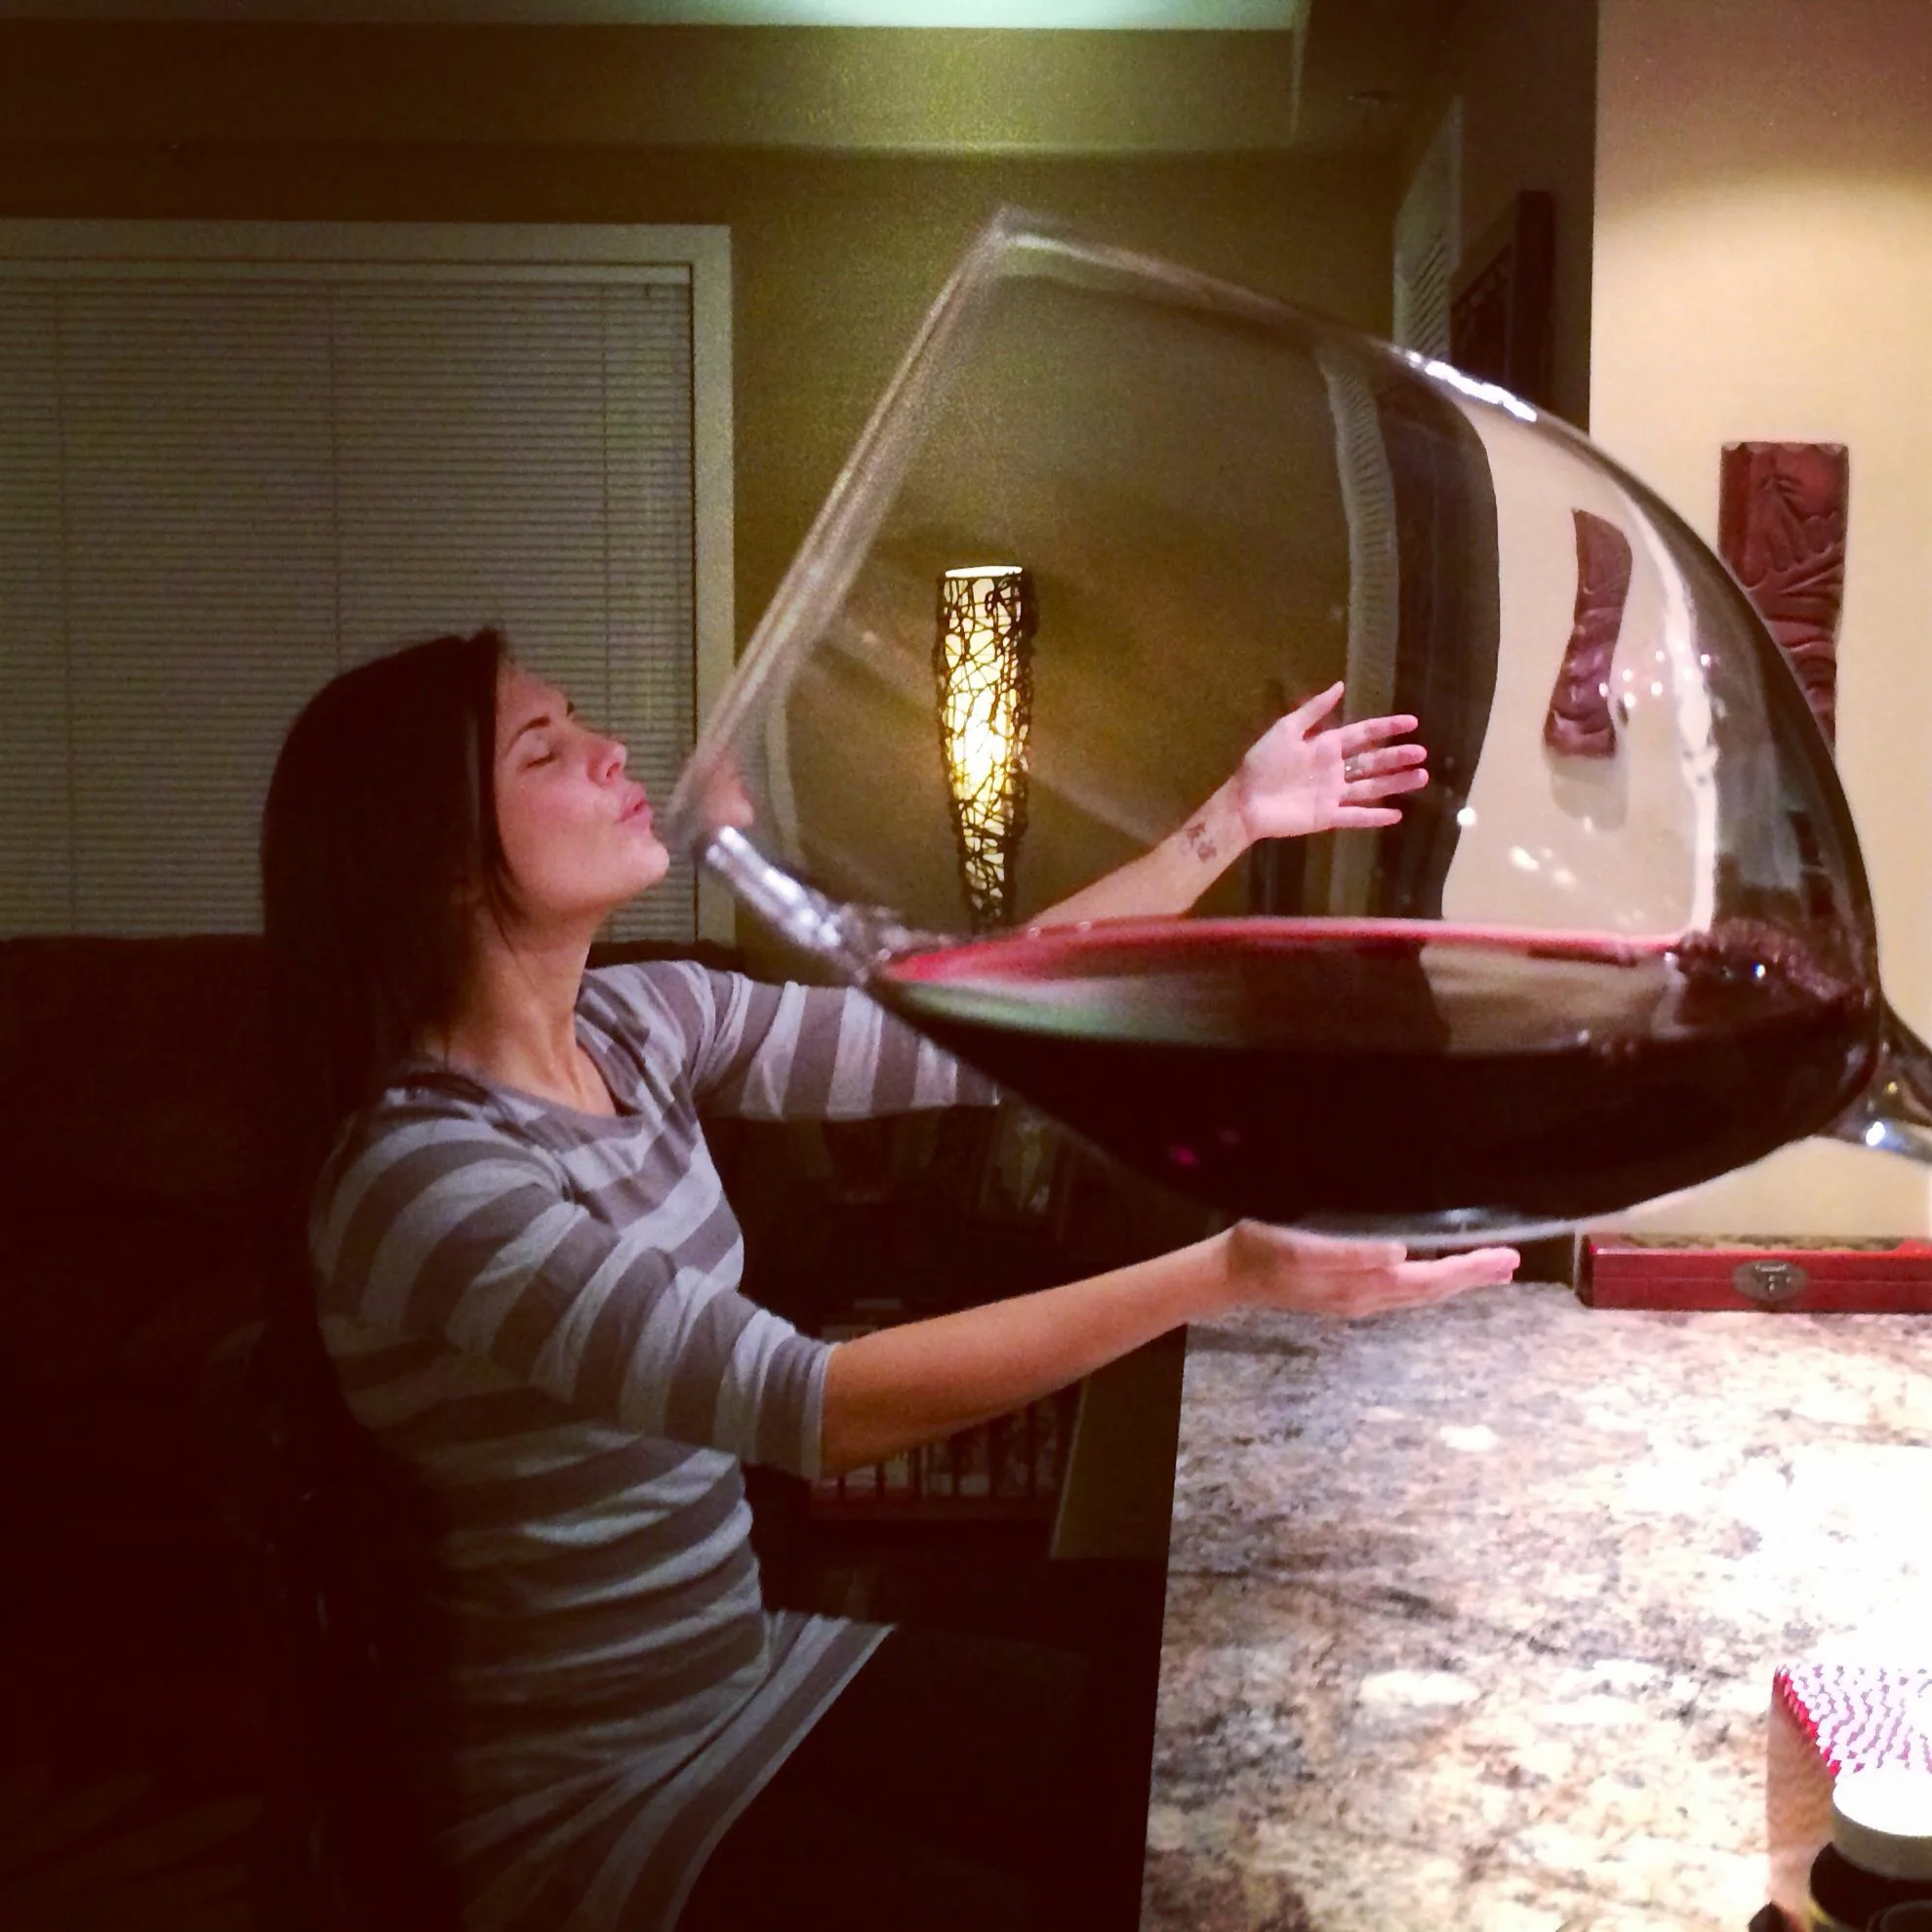

In [1]:
import warnings; warnings.simplefilter('ignore')
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import loguniform, randint

from sklearn.model_selection import (train_test_split, KFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, cross_validate, validation_curve, ParameterGrid)
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
sns.set(style='darkgrid'); plt.rcParams['figure.figsize'] = (8, 4)
N_JOBS = -1

## 1. Данные и честное разбиение

Данные те же, что в лабе №1: красные и белые вина, объединённые с признаком `is_red`. В лабе №1 (раздел 8) было показано, что ~18% строк — полные дубликаты, и из-за них деревья «вспоминают» тестовые объекты. Для подбора гиперпараметров это особенно опасно: дубликаты попадут в разные folds CV, и CV станет оптимистичным именно для сложных моделей, то есть сместит выбор в сторону переобучения. Поэтому **дубликаты удаляю до разбиения**.

Дальше: один раз делим на train/test (80/20, стратификация по `quality`, `random_state=42`, как в лабе №1). Всё, что связано с выбором параметров, идёт только на train. Test открывается один раз в разделе 8.

In [2]:
red = pd.read_csv('../regression/winequality-red.csv', sep=';'); red['is_red'] = 1
white = pd.read_csv('../regression/winequality-white.csv', sep=';'); white['is_red'] = 0
df_all = pd.concat([red, white], ignore_index=True)
df = df_all.drop_duplicates().reset_index(drop=True)
print('Всего строк:', len(df_all), '| после удаления дубликатов:', len(df))

X, y = df.drop(columns='quality'), df['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('train:', X_train.shape, '| test:', X_test.shape)

def rmse(a, b): return np.sqrt(mean_squared_error(a, b))

Всего строк: 6497 | после удаления дубликатов: 5320
train: (4256, 12) | test: (1064, 12)


## 2. Baseline: исходная модель

Baseline — `GradientBoostingRegressor` с параметрами по умолчанию (только `random_state` зафиксирован). Это та самая «исходная модель», относительно которой оценивается любая оптимизация. 

In [3]:
# единая схема CV для ВСЕХ экспериментов — только на train
K = 5
cv = KFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)

base_params = GradientBoostingRegressor().get_params()
show = ['n_estimators', 'learning_rate', 'max_depth', 'min_samples_leaf', 'min_samples_split', 'subsample', 'max_features', 'loss']
print('Параметры baseline:', {k: base_params[k] for k in show})

baseline = GradientBoostingRegressor(random_state=RANDOM_STATE)
t = time.time()
cv_base = -cross_val_score(baseline, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=N_JOBS)
print('Baseline CV RMSE по folds:', cv_base.round(4))
print('Baseline CV RMSE: %.4f ± %.4f  (%.1f c)' % (cv_base.mean(), cv_base.std(), time.time() - t))

Параметры baseline: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2, 'subsample': 1.0, 'max_features': None, 'loss': 'squared_error'}


Baseline CV RMSE по folds: [0.6914 0.7035 0.696  0.7205 0.7214]
Baseline CV RMSE: 0.7066 ± 0.0124  (3.5 c)


> Test для baseline **не считаю сейчас** — он понадобится только в финальной таблице (раздел 8), чтобы не заглядывать в него раньше времени.

## 3. Гиперпараметры

Выбираю **четыре** параметра Gradient Boosting. Больше не нужно: цель — понять влияние, а не раздуть пространство поиска.

| Параметр | Смысл | Диапазон | Ожидаемое влияние |
|---|---|---|---|
| `n_estimators` | число деревьев (шагов бустинга) | 50–800 | мало деревьев — недообучение; много — модель дообучается до шума train, CV-ошибка сначала падает, затем выходит на плато или растёт |
| `learning_rate` | вклад каждого дерева (шаг) | 0.01–0.5 | маленький шаг требует много деревьев, но сглаживает; большой — быстро учится, но «перепрыгивает» и переобучается. Параметр **связан** с `n_estimators` |
| `max_depth` | глубина каждого дерева = порядок взаимодействий признаков | 2–10 | мелкие деревья — простая модель (смещение); глубокие запоминают шум (дисперсия) |
| `subsample` | доля объектов для каждого дерева | 0.5–1.0 | <1 вносит случайность (стохастический бустинг) и действует как регуляризация |

Остальные (`min_samples_leaf`, `max_features` и т.д.) оставляю по умолчанию, чтобы не размывать эксперимент.

## 4. Кросс-валидация

**Выбор числа folds.** Беру **K = 5** с перемешиванием (`shuffle=True`, фиксированный `random_state`). На train 4250 объектов, значит на каждый fold валидации приходится ~850, а на обучение — ~3400. Это компромисс: K=3 учит модель на меньшей доле данных (оценка смещена в пессимистичную сторону), K=10 даёт почти несмещённую оценку, но вдвое дороже, а с каждым fold'ом в Grid Search запускается десятки обучений. Деревья бустинга дорогие, поэтому 5 — разумный баланс смещения, дисперсии оценки и времени. Стратификация для регрессии не нужна; классы `quality` и так распределены равномерно из-за shuffle. Один и тот же `cv` используется во всех поисках, чтобы результаты были сопоставимы.

**Зачем нужна кросс-валидация.** Она оценивает качество модели на данных, которые модель не видела при обучении, усредняя по нескольким разбиениям: получаем не одну цифру, а набор оценок (среднее и разброс), и используем все train-данные и для обучения, и для проверки.

**Почему одного разбиения train/test (или train/val) недостаточно для подбора.** Оценка по одному разбиению зависит от того, какие именно объекты попали в валидацию: при разных разбиениях RMSE «плавает» (ниже мы увидим разброс по folds порядка сотых). Выбирая лучший параметр по одной такой оценке, мы можем выбрать тот, кому просто повезло на этих объектах, а не тот, который лучше в целом. А если для этого использовать test, то мы ещё и лишаемся честной финальной проверки.

**Что будет, если многократно выбирать гиперпараметры по test.** Test превращается в ещё одну валидационную выборку: из множества кандидатов выигрывает тот, кто лучше подошёл именно к этим объектам (отбор по шуму, «selection bias» / winner's curse). Итоговая оценка становится оптимистичной и не отражает качество на новых данных, а честной проверки не остаётся. Чем больше кандидатов перебрано, тем сильнее смещение. Ниже в разделе 8 это можно увидеть и количественно: оценка улучшения по CV и по test не обязана совпадать (см. сравнение CV и test в таблице).

## 5. Grid Search

Сетка 3 × 3 × 3 = 27 комбинаций по трём главным параметрам (`n_estimators`, `learning_rate`, `max_depth`); `subsample` на сетке не варьирую (оставляю 1.0), а исследую его отдельно и использую в Random Search, где добавление измерения почти не стоит денег. Для сетки значения выбраны вручную по порядку величины.

In [4]:
param_grid = {
    'n_estimators':  [100, 200, 400],
    'learning_rate': [0.03, 0.1, 0.3],
    'max_depth':     [2, 4, 6],
}
n_grid = len(ParameterGrid(param_grid))
print('Комбинаций в сетке:', n_grid, '| всего обучений (×%d folds): %d' % (K, n_grid * K))

grid = GridSearchCV(GradientBoostingRegressor(random_state=RANDOM_STATE), param_grid, cv=cv,
                    scoring='neg_root_mean_squared_error', n_jobs=N_JOBS, return_train_score=True, refit=True)
t = time.time(); grid.fit(X_train, y_train); t_grid = time.time() - t

print('Время Grid Search: %.1f c' % t_grid)
print('Лучшие параметры:', grid.best_params_)
print('CV RMSE лучшего: %.4f ± %.4f' % (-grid.best_score_, grid.cv_results_['std_test_score'][grid.best_index_]))

gres = pd.DataFrame(grid.cv_results_)
gres['cv_rmse'] = -gres.mean_test_score; gres['train_rmse'] = -gres.mean_train_score
display(gres.sort_values('cv_rmse')[['param_n_estimators', 'param_learning_rate', 'param_max_depth', 'cv_rmse', 'train_rmse', 'std_test_score', 'mean_fit_time']].head(8).round(4))

Комбинаций в сетке: 27 | всего обучений (×5 folds): 135


Время Grid Search: 134.9 c
Лучшие параметры: {'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 200}
CV RMSE лучшего: 0.6989 ± 0.0114


,param_n_estimators,param_learning_rate,param_max_depth,cv_rmse,train_rmse,std_test_score,mean_fit_time
7,200,0.03,6,0.6989,0.4818,0.0114,2.3020
8,400,0.03,6,0.7012,0.3945,0.0120,4.6759
12,100,0.10,4,0.7014,0.5761,0.0117,0.8563
15,100,0.10,6,0.7024,0.4154,0.0117,1.1675
6,100,0.03,6,0.7028,0.5467,0.0132,1.1122
4,200,0.03,4,0.7030,0.6109,0.0129,1.5898
5,400,0.03,4,0.7031,0.5643,0.0108,3.5505
11,400,0.10,2,0.7076,0.6149,0.0104,1.8291


## 6. Random Search

Для сопоставимости бюджет тот же: **27 случайных комбинаций × 5 folds = 135 обучений**. Параметры берутся из распределений: `learning_rate` — логарифмически равномерно (порядок величины важнее абсолютного шага), `n_estimators` и `max_depth` — целые равномерные, `subsample` — равномерно. Пространство поиска шире сетки (непрерывные значения, лишнее измерение `subsample`).

In [5]:
param_dist = {
    'n_estimators':  randint(50, 601),
    'learning_rate': loguniform(0.01, 0.5),
    'max_depth':     randint(2, 9),
    'subsample':     [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
}
N_ITER = n_grid   # тот же бюджет по числу комбинаций
rnd = RandomizedSearchCV(GradientBoostingRegressor(random_state=RANDOM_STATE), param_dist, n_iter=N_ITER, cv=cv,
                         scoring='neg_root_mean_squared_error', n_jobs=N_JOBS, random_state=RANDOM_STATE,
                         return_train_score=True, refit=True)
t = time.time(); rnd.fit(X_train, y_train); t_rnd = time.time() - t

print('Время Random Search: %.1f c' % t_rnd)
print('Лучшие параметры:', rnd.best_params_)
print('CV RMSE лучшего: %.4f ± %.4f' % (-rnd.best_score_, rnd.cv_results_['std_test_score'][rnd.best_index_]))

rres = pd.DataFrame(rnd.cv_results_)
rres['cv_rmse'] = -rres.mean_test_score; rres['train_rmse'] = -rres.mean_train_score
display(rres.sort_values('cv_rmse')[['param_n_estimators', 'param_learning_rate', 'param_max_depth', 'param_subsample', 'cv_rmse', 'train_rmse', 'std_test_score', 'mean_fit_time']].head(8).round(4))

Время Random Search: 169.0 c
Лучшие параметры: {'learning_rate': np.float64(0.015734685129393678), 'max_depth': 8, 'n_estimators': 250, 'subsample': 0.8}
CV RMSE лучшего: 0.6902 ± 0.0130


,param_n_estimators,param_learning_rate,param_max_depth,param_subsample,cv_rmse,train_rmse,std_test_score,mean_fit_time
25,250,0.0157,8,0.8,0.6902,0.3633,0.0130,3.2184
16,451,0.0206,8,0.6,0.6918,0.2279,0.0126,4.7759
15,155,0.0528,7,0.8,0.6946,0.3284,0.0141,1.9111
12,416,0.0247,5,0.8,0.6947,0.4801,0.0141,3.6765
23,468,0.0218,4,0.5,0.6952,0.5645,0.0120,2.2859
0,320,0.0433,6,0.7,0.6970,0.3264,0.0099,2.8672
5,363,0.0205,5,1.0,0.6994,0.5376,0.0106,3.4533
21,114,0.0174,8,0.5,0.6997,0.5220,0.0159,1.1064


,комбинаций,обучений,"время, c",лучший CV RMSE,худший CV RMSE в поиске,медиана CV RMSE
Grid Search,27.0,135.0,134.9061,0.6989,0.7569,0.7124
Random Search,27.0,135.0,168.9630,0.6902,0.7948,0.7094


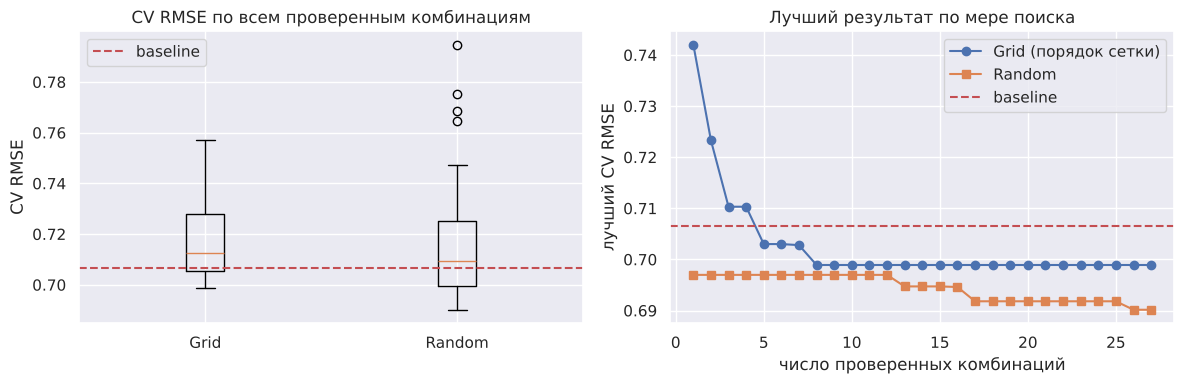

In [6]:
cmp_ = pd.DataFrame({
    'Grid Search':   {'комбинаций': n_grid, 'обучений': n_grid * K, 'время, c': t_grid, 'лучший CV RMSE': -grid.best_score_,
                      'худший CV RMSE в поиске': gres.cv_rmse.max(), 'медиана CV RMSE': gres.cv_rmse.median()},
    'Random Search': {'комбинаций': N_ITER, 'обучений': N_ITER * K, 'время, c': t_rnd, 'лучший CV RMSE': -rnd.best_score_,
                      'худший CV RMSE в поиске': rres.cv_rmse.max(), 'медиана CV RMSE': rres.cv_rmse.median()},
}).T
display(cmp_.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# разброс качества по всем проверенным комбинациям
ax[0].boxplot([gres.cv_rmse, rres.cv_rmse], tick_labels=['Grid', 'Random'])
ax[0].axhline(cv_base.mean(), color='r', ls='--', label='baseline'); ax[0].legend()
ax[0].set_ylabel('CV RMSE'); ax[0].set_title('CV RMSE по всем проверенным комбинациям')
# лучший найденный результат по ходу поиска (кумулятивный минимум)
ax[1].plot(range(1, n_grid + 1), np.minimum.accumulate(gres.cv_rmse.values), 'o-', label='Grid (порядок сетки)')
ax[1].plot(range(1, N_ITER + 1), np.minimum.accumulate(rres.cv_rmse.values), 's-', label='Random')
ax[1].axhline(cv_base.mean(), color='r', ls='--', label='baseline'); ax[1].legend()
ax[1].set_xlabel('число проверенных комбинаций'); ax[1].set_ylabel('лучший CV RMSE'); ax[1].set_title('Лучший результат по мере поиска')
plt.tight_layout(); plt.show()

**Сравнение Grid и Random.**

| | Grid Search | Random Search |
|---|---|---|
| проверено комбинаций | 27 (135 обучений) | 27 (135 обучений) |
| лучший CV RMSE | 0.6989 (`lr=0.03, depth=6, n=200`) | **0.6902** (`lr=0.016, depth=8, n=250, subsample=0.8`) |
| время | 124 с | 164 с |

- **Качество.** Random нашёл CV RMSE 0.690 против 0.699 у Grid при одинаковом числе комбинаций. Но разница 0.009 меньше разброса по folds (~0.013), так что это скорее «чуть лучше», чем «однозначно лучше».
- **Почему так вышло.** У Grid лучший набор лежит **на краю сетки** (`lr=0.03` — минимальное значение, `max_depth=6` — максимальное): оптимум, вероятно, за пределами заданных значений. Random Search достал точки вне узлов сетки (`lr=0.016`, `depth=8`) и добавил измерение `subsample=0.8`, которое на сетке не варьировалось. То есть выигрыш даёт не «магия случайности», а то, что пространство шире и точки не привязаны к узлам.
- **Время.** Число обучений одинаково, но Random потратил больше (164 с против 124 с), потому что случайно попадаются более тяжёлые конфигурации (глубина до 8, до 600 деревьев), а в сетке максимум 400 деревьев при глубине 6. Время определяется не числом комбинаций, а их «стоимостью».
- **Разброс качества по комбинациям.** Медианы CV RMSE почти одинаковы (0.712 у Grid, 0.709 у Random), но у Random хуже худшая комбинация (0.795 против 0.757): широкий диапазон включает и плохие значения (слишком большой `learning_rate`).
- Один запуск Random Search зависит от `random_state`; для серьёзного вывода «что лучше» нужно несколько запусков.

**Когда случайный поиск предпочтительнее полного перебора.** (1) Когда параметров много, а значимы из них лишь некоторые: сетка из m значений по d параметрам стоит m^d, и значимый параметр пробуется всего m раз, а при случайном поиске каждая из n комбинаций даёт новое значение каждого параметра (n различных значений, а не m). (2) Когда параметры непрерывные или у них широкий диапазон: случайный поиск не привязан к узлам заданной сетки и может попасть между ними. (3) Когда бюджет ограничен и его нужно задать явно (`n_iter`), и поиск можно остановить в любой момент. Если параметров 2–3 и их диапазон понятен (как в сетке выше), сетка допустима и даёт воспроизводимую «карту» качества.

## 7. Влияние гиперпараметров

Для каждого параметра меняю его значение, остальные фиксирую на **найденном лучшем наборе** (лучший из Grid/Random по CV), и смотрю на **train RMSE** и **CV RMSE**. Расхождение между ними — признак переобучения: если train падает, а CV растёт или стоит на месте, модель запоминает шум. Всё считается только на train с той же схемой `cv`.

Опорный набор для кривых (лучший по CV, Random): {'learning_rate': np.float64(0.015734685129393678), 'max_depth': 8, 'n_estimators': 250, 'subsample': 0.8}


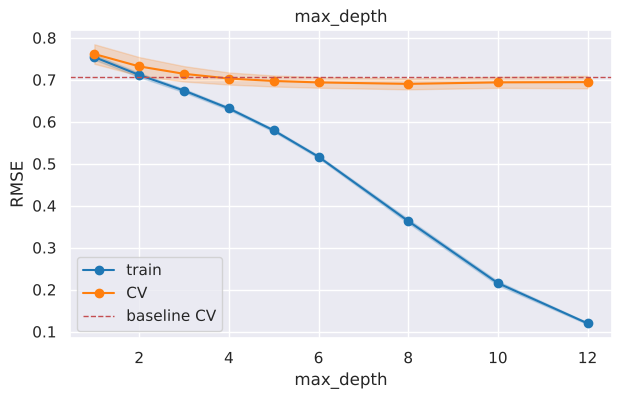

,train,cv,cv_std
1,0.7539,0.7612,0.0232
2,0.7114,0.7318,0.0221
3,0.6741,0.7141,0.0183
4,0.6317,0.7029,0.0144
5,0.5793,0.6971,0.0131
6,0.5165,0.6936,0.0127
8,0.3633,0.6902,0.0130
10,0.2155,0.6938,0.0131
12,0.1197,0.6944,0.0148


In [7]:
best_cv_is_grid = -grid.best_score_ <= -rnd.best_score_
best_search = grid if best_cv_is_grid else rnd
best_params = dict(best_search.best_params_)
print('Опорный набор для кривых (лучший по CV, %s):' % ('Grid' if best_cv_is_grid else 'Random'), best_params)

def curve(name, values, log=False, title=None):
    est = GradientBoostingRegressor(random_state=RANDOM_STATE, **{k: v for k, v in best_params.items() if k != name})
    tr, va = validation_curve(est, X_train, y_train, param_name=name, param_range=values, cv=cv,
                              scoring='neg_root_mean_squared_error', n_jobs=N_JOBS)
    tr, va = -tr, -va
    plt.figure(figsize=(7, 4))
    for s, lab, c in [(tr, 'train', 'tab:blue'), (va, 'CV', 'tab:orange')]:
        plt.plot(values, s.mean(1), 'o-', color=c, label=lab)
        plt.fill_between(values, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=c, alpha=0.2)
    if log: plt.xscale('log')
    plt.axhline(cv_base.mean(), color='r', ls='--', lw=1, label='baseline CV')
    plt.xlabel(name); plt.ylabel('RMSE'); plt.title(title or name); plt.legend(); plt.show()
    return pd.DataFrame({'train': tr.mean(1), 'cv': va.mean(1), 'cv_std': va.std(1)}, index=values).round(4)

t_max_depth = curve('max_depth', [1, 2, 3, 4, 5, 6, 8, 10, 12], title='max_depth'); display(t_max_depth)

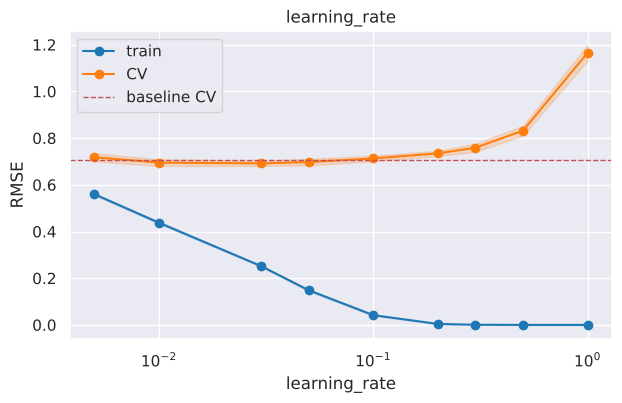

,train,cv,cv_std
0.005,0.5596,0.7180,0.0172
0.010,0.4377,0.6951,0.0143
0.030,0.2517,0.6917,0.0108
0.050,0.1485,0.6975,0.0140
0.100,0.0418,0.7129,0.0114
0.200,0.0042,0.7345,0.0117
0.300,0.0006,0.7589,0.0171
0.500,0.0000,0.8321,0.0210
1.000,0.0000,1.1649,0.0342


In [8]:
t_lr = curve('learning_rate', [0.005, 0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0], log=True, title='learning_rate'); display(t_lr)

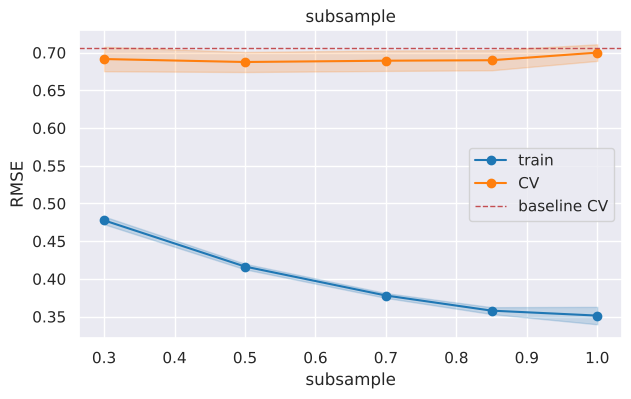

,train,cv,cv_std
0.30,0.4776,0.6915,0.0162
0.50,0.4164,0.6875,0.0133
0.70,0.3780,0.6893,0.0136
0.85,0.3579,0.6899,0.0133
1.00,0.3514,0.7000,0.0110


In [9]:
t_sub = curve('subsample', [0.3, 0.5, 0.7, 0.85, 1.0], title='subsample'); display(t_sub)

`n_estimators` исследую иначе: бустинг строит дерево за деревом, поэтому по **одной** обученной модели можно получить качество для любого числа деревьев через `staged_predict` (без десятков повторных обучений). Показываю три значения `learning_rate`, чтобы увидеть связь двух параметров.

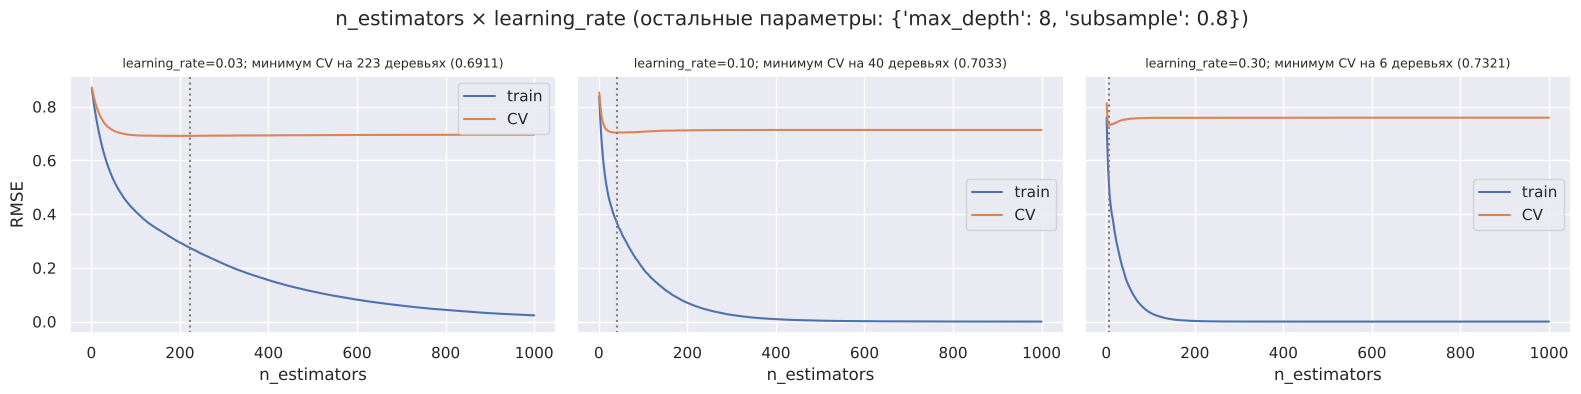

In [10]:
def staged_curve(lr, n_max=1000, **kw):
    tr_all, va_all = [], []
    for tr_i, va_i in cv.split(X_train):
        m = GradientBoostingRegressor(random_state=RANDOM_STATE, n_estimators=n_max, learning_rate=lr, **kw)
        m.fit(X_train.iloc[tr_i], y_train.iloc[tr_i])
        tr_all.append([rmse(y_train.iloc[tr_i], p) for p in m.staged_predict(X_train.iloc[tr_i])])
        va_all.append([rmse(y_train.iloc[va_i], p) for p in m.staged_predict(X_train.iloc[va_i])])
    return np.mean(tr_all, 0), np.mean(va_all, 0)

other = {k: v for k, v in best_params.items() if k in ('max_depth', 'subsample')}
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
staged = {}
for a, lr in zip(ax, [0.03, 0.1, 0.3]):
    tr, va = staged_curve(lr, **other); staged[lr] = (tr, va)
    a.plot(np.arange(1, len(tr) + 1), tr, label='train'); a.plot(np.arange(1, len(va) + 1), va, label='CV')
    a.axvline(va.argmin() + 1, color='gray', ls=':'); a.set_title('learning_rate=%.2f; минимум CV на %d деревьях (%.4f)' % (lr, va.argmin() + 1, va.min()), fontsize=9)
    a.set_xlabel('n_estimators'); a.legend()
ax[0].set_ylabel('RMSE'); plt.suptitle('n_estimators × learning_rate (остальные параметры: %s)' % other); plt.tight_layout(); plt.show()

**Интерпретация (по таблицам и графикам выше; на CV, остальные параметры зафиксированы на опорном наборе).**

| Параметр | Недообучение | Разумная сложность | Переобучение |
|---|---|---|---|
| `max_depth` | глубина 1–3: train 0.75→0.67 и CV 0.76→0.71 высоки и близки друг к другу, модель слишком проста | 5–10: CV на плато 0.690–0.697 (минимум на 8) | >8: train падает до 0.12, а CV почти не меняется (0.694): запоминание шума, но без заметного ущерба |
| `learning_rate` (при 250 деревьях) | ≤0.005: train 0.56, CV 0.718 — за 250 деревьев модель не успевает научиться | 0.01–0.05: CV 0.692–0.698 (минимум на 0.03) | ≥0.1: train→0, CV растёт 0.713→0.759→0.832→1.165 при 1.0 — модель быстро запоминает train |
| `n_estimators` | малое число деревьев (при `lr=0.03` — меньше ~100): CV ещё снижается | `lr=0.03`: минимум CV на ~220 деревьях (0.691), затем плато; `lr=0.1`: минимум на ~40 (0.703); `lr=0.3`: на ~6 (0.732) | `lr=0.1`: после минимума CV растёт до 0.713; `lr=0.3` — до 0.759; `lr=0.03` — очень медленно (0.696 на 1000) |
| `subsample` | — | 0.3–0.85: CV 0.688–0.692 | 1.0: CV 0.700, чуть хуже; subsample<1 работает как регуляризация |

**Объяснение.**
- **Gap между train и CV — мера переобучения.** Глубина и малый `learning_rate` быстро уменьшают train RMSE, а CV выходит на плато: деревья в бустинге при росте сложности «упираются» в шум оценок дегустаторов (минимальная достижимая ошибка здесь порядка 0.69).
- **`learning_rate` и `n_estimators` связаны.** Чем меньше шаг, тем больше деревьев нужно и тем ниже минимум CV: 0.691 (lr=0.03) против 0.703 (lr=0.1) и 0.732 (lr=0.3). Большой шаг «перескакивает» оптимум и быстро переобучается, поэтому оптимум по `n_estimators` у него наступает очень рано. Подбирать их по отдельности нельзя — только совместно (или через раннюю остановку).
- **`subsample<1`** добавляет случайность: каждое дерево видит разные объекты, ошибки деревьев меньше коррелируют, и ансамбль усредняет их лучше. Эффект небольшой (~0.01), сравним с разбросом по folds, поэтому его надёжность ограничена.
- Самый чувствительный параметр — `learning_rate` (диапазон CV 0.69–1.16); наименее — `max_depth` в диапазоне 5–12 (0.690–0.697).

## 8. Финальная модель: единственное обращение к test

Только теперь, когда оба поиска завершены, а параметры выбраны по CV на train, обучаем три модели на **всём train** и **один раз** считаем качество на test: исходную (baseline), лучшую по Grid Search и лучшую по Random Search. `refit=True` в поисках уже переобучил модели на всём train. Для сопоставимости baseline тоже обучается на всём train.

In [11]:
baseline.fit(X_train, y_train)
final = {'Baseline (по умолчанию)': baseline, 'Grid Search (лучший)': grid.best_estimator_, 'Random Search (лучший)': rnd.best_estimator_}

def fold_scores(model):
    return -cross_val_score(model, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=N_JOBS)

rows, folds = [], {}
for name, m in final.items():
    f = fold_scores(m.set_params()); folds[name] = f
    p = m.predict(X_test)
    rows.append({'Модель': name, 'CV RMSE': f.mean(), 'CV std': f.std(), 'Test RMSE': rmse(y_test, p), 'Test MAE': mean_absolute_error(y_test, p),
                 'Test − CV': rmse(y_test, p) - f.mean()})
final_tbl = pd.DataFrame(rows).set_index('Модель'); display(final_tbl.round(4))
print('Параметры Grid:  ', grid.best_params_); print('Параметры Random:', rnd.best_params_)

,CV RMSE,CV std,Test RMSE,Test MAE,Test − CV
Модель,,,,,
Baseline (по умолчанию),0.7066,0.0124,0.6943,0.5391,-0.0122
Grid Search (лучший),0.6989,0.0114,0.6930,0.5361,-0.0059
Random Search (лучший),0.6902,0.0130,0.6854,0.5303,-0.0047


Параметры Grid:   {'learning_rate': 0.03, 'max_depth': 6, 'n_estimators': 200}
Параметры Random: {'learning_rate': np.float64(0.015734685129393678), 'max_depth': 8, 'n_estimators': 250, 'subsample': 0.8}


In [12]:
# неопределённость test-оценки: bootstrap по тестовым объектам (модели не переобучаются)
rng = np.random.RandomState(RANDOM_STATE); yt = y_test.values
preds = {n: m.predict(X_test) for n, m in final.items()}
idx = [rng.randint(0, len(yt), len(yt)) for _ in range(1000)]
boot = {n: np.array([rmse(yt[i], p[i]) for i in idx]) for n, p in preds.items()}
for n, b in boot.items(): print('%-26s Test RMSE 95%% ДИ: [%.3f, %.3f]' % (n, *np.percentile(b, [2.5, 97.5])))
d = boot['Baseline (по умолчанию)'] - boot['Grid Search (лучший)']; print('Улучшение Grid vs baseline: среднее %.4f, 95%% ДИ [%.4f, %.4f]' % (d.mean(), *np.percentile(d, [2.5, 97.5])))
d = boot['Baseline (по умолчанию)'] - boot['Random Search (лучший)']; print('Улучшение Random vs baseline: среднее %.4f, 95%% ДИ [%.4f, %.4f]' % (d.mean(), *np.percentile(d, [2.5, 97.5])))
d = boot['Grid Search (лучший)'] - boot['Random Search (лучший)']; print('Grid − Random: среднее %.4f, 95%% ДИ [%.4f, %.4f]' % (d.mean(), *np.percentile(d, [2.5, 97.5])))

Baseline (по умолчанию)    Test RMSE 95% ДИ: [0.657, 0.731]
Grid Search (лучший)       Test RMSE 95% ДИ: [0.655, 0.732]
Random Search (лучший)     Test RMSE 95% ДИ: [0.647, 0.725]
Улучшение Grid vs baseline: среднее 0.0014, 95% ДИ [-0.0090, 0.0114]
Улучшение Random vs baseline: среднее 0.0089, 95% ДИ [-0.0034, 0.0209]
Grid − Random: среднее 0.0075, 95% ДИ [0.0006, 0.0151]


| Модель | CV RMSE | Test RMSE |
|---|---|---|
| Baseline (по умолчанию) | 0.7066 | 0.6943 |
| Grid Search | 0.6989 | 0.6930 |
| Random Search | **0.6902** | **0.6854** |

**Насколько оптимизация улучшила качество.** По CV: Grid −0.008, Random −0.016 относительно baseline. На test: Grid −0.001, Random −0.009. То есть улучшение есть, но **скромное** (1–2% по RMSE): параметры по умолчанию у Gradient Boosting на этих данных уже близки к разумным, а основная часть ошибки — шум самих оценок.

**Совпадает ли улучшение на CV с test.** Направление совпадает (Random < Grid < baseline в обоих случаях), но размер — нет: на CV выигрыш Grid 0.008, а на test лишь 0.001. Bootstrap-интервалы улучшения (baseline − модель) включают ноль: для Grid [−0.009, 0.011], для Random [−0.003, 0.021]. Значит, **на test улучшение статистически не подтверждено**; единственная пара, где интервал почти не включает ноль, — Grid и Random (Grid − Random: 0.0075, ДИ [0.0006, 0.015], граница интервала близка к нулю).

**Чем объясняется расхождение.**
1. **Шум оценки на test.** 1064 объекта дают 95% ДИ RMSE примерно ±0.04, что в разы больше улучшения в 0.01.
2. **Selection bias.** Лучшее значение CV (min по 27 комбинациям) оптимистично: из многих кандидатов выбран тот, кому повезло на этих folds. Часть выигрыша 0.016 — это отбор по шуму, и на новых данных его не будет.
3. **Test не обязан быть «тем же уровнем сложности».** У всех трёх моделей test RMSE ниже CV (на 0.005–0.012): test-выборка оказалась чуть «легче» train-folds. Это одинаково сдвигает все модели и не влияет на ранжирование, но сжимает видимую разницу.
4. Разница между моделями на test мала, поэтому порядок Grid/Random мог бы поменяться на другом разбиении.

Честный вывод: **подбор помог чуть-чуть и стабильно по CV, но надёжно подтвердить это на test нельзя**; практической пользы от подбора больше всего дало отказ от слишком большого `learning_rate` и добавление `subsample`, а не тонкая настройка.

## 9. Анализ устойчивости

Смотрим не только на среднее CV, но и на результаты отдельных folds.

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,max−min
Baseline (по умолчанию),0.6914,0.7035,0.6960,0.7205,0.7214,0.7066,0.0138,0.0300
Grid Search (лучший),0.6845,0.6948,0.6918,0.7071,0.7165,0.6989,0.0128,0.0320
Random Search (лучший),0.6753,0.6839,0.6801,0.7065,0.7050,0.6902,0.0146,0.0311


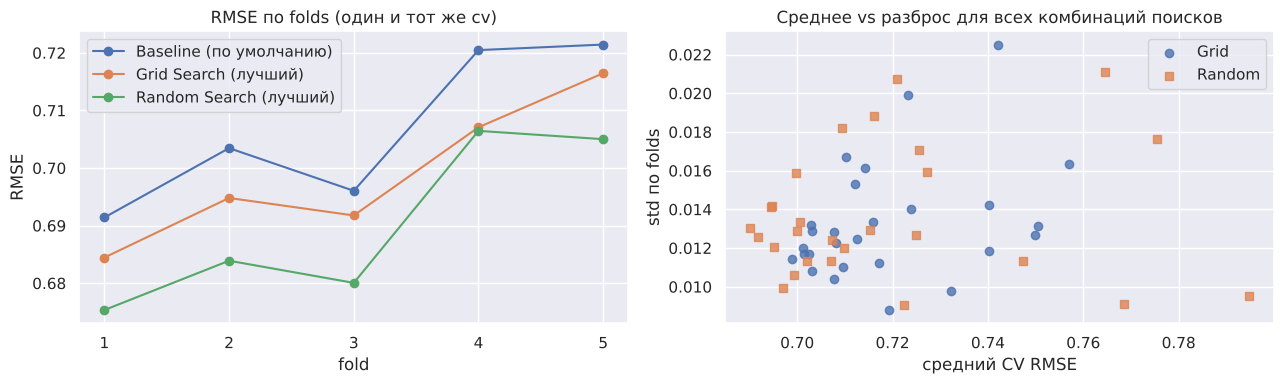

                           mean     std     min     max
Baseline (по умолчанию)  0.7073  0.0141  0.6834  0.7331
Grid Search (лучший)     0.6998  0.0132  0.6770  0.7232
Random Search (лучший)   0.6919  0.0158  0.6668  0.7217


In [13]:
ft = pd.DataFrame(folds, index=['fold %d' % (i + 1) for i in range(K)]).T
ft['mean'] = ft.mean(1); ft['std'] = ft.iloc[:, :K].std(1); ft['max−min'] = ft.iloc[:, :K].max(1) - ft.iloc[:, :K].min(1)
display(ft.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n, f in folds.items(): ax[0].plot(range(1, K + 1), f, 'o-', label=n)
ax[0].set_xticks(range(1, K + 1)); ax[0].set_xlabel('fold'); ax[0].set_ylabel('RMSE'); ax[0].set_title('RMSE по folds (один и тот же cv)'); ax[0].legend()
# внутри самого поиска: средний RMSE vs std по всем комбинациям
ax[1].scatter(gres.cv_rmse, gres.std_test_score, label='Grid', alpha=.8); ax[1].scatter(rres.cv_rmse, rres.std_test_score, label='Random', marker='s', alpha=.8)
ax[1].set_xlabel('средний CV RMSE'); ax[1].set_ylabel('std по folds'); ax[1].set_title('Среднее vs разброс для всех комбинаций поисков'); ax[1].legend()
plt.tight_layout(); plt.show()

# повторная CV с другими разбиениями — насколько результат зависит от самой нарезки
from sklearn.model_selection import RepeatedKFold
rkf = RepeatedKFold(n_splits=K, n_repeats=3, random_state=7)
rep = {n: -cross_val_score(m, X_train, y_train, cv=rkf, scoring='neg_root_mean_squared_error', n_jobs=N_JOBS) for n, m in final.items()}
print(pd.DataFrame({n: {'mean': r.mean(), 'std': r.std(), 'min': r.min(), 'max': r.max()} for n, r in rep.items()}).T.round(4))

**Что видно по folds.**
- Разброс по folds одного порядка у всех моделей: std 0.013–0.015, max−min около 0.03. Это больше, чем разница между средними (0.008–0.016), поэтому сравнивать модели «по средним» без учёта разброса рискованно.
- Но folds для всех моделей **общие** (один `cv`), и они «трудные» одинаково: fold 1 — самый лёгкий, folds 4–5 — самые тяжёлые у всех трёх моделей. Поэтому надёжнее сравнивать **попарно по folds**: Grid лучше baseline на всех 5 folds (на 0.004–0.013), Random лучше baseline на всех 5 folds (на 0.014–0.020) и лучше Grid на всех 5. Консистентный выигрыш на каждом fold гораздо убедительнее, чем различие средних на фоне общего разброса.
- Повторная CV с другими разбиениями (3×5 folds) даёт ту же картину: средние 0.707 / 0.700 / 0.692, std 0.014 / 0.013 / 0.016; у Random Search разброс чуть больше, а диапазон [0.667; 0.722] шире, чем у Grid [0.677; 0.723]. То есть лучшее среднее достигнуто ценой чуть менее стабильного результата.

**Почему две модели с одинаковым средним могут различаться по устойчивости.** Среднее скрывает распределение: одна модель может давать ровные 0.69 на всех folds, другая — 0.65 на одних и 0.73 на других. Разброс отражает дисперсию модели: чувствительность к конкретной выборке обучения (глубокие деревья и малая доля `subsample` сильнее зависят от того, какие объекты попали в train) и к «сложным» объектам в валидации. На практике при равных средних предпочитают модель с меньшим std (она предсказуемее на новых данных), а при близких средних иногда применяют правило «одного стандартного отклонения» — выбирают более простую модель в пределах одного std от лучшей.

## 10. Честный эксперимент: чек-лист

- Test **не использовался** для выбора параметров: все поиски, кривые и выбор опорного набора выполнены только на train с кросс-валидацией; к test обращение — один раз в разделе 8.
- Все три модели сравнивались на **одном и том же** разбиении и одной схеме `cv`.
- Baseline зафиксирован (параметры по умолчанию, раздел 2) и включён в финальную таблицу.
- Дубликаты удалены **до** разбиения, поэтому копии одного вина не попадают одновременно в train и валидацию/тест (в лабе №1 было показано, что это завышало качество деревьев).
- Целевая переменная не входит в признаки; препроцессинга, обучаемого на всём датасете, нет (деревьям масштабирование не нужно).
- Что осталось несовершенным: CV внутри поиска использована и для выбора, и для оценки лучшего CV-значения, поэтому оно слегка оптимистично (selection bias) — именно поэтому финальное сравнение делается на отложенном test.

## 11. Итоги

| Модель | CV RMSE | CV std | Test RMSE |
|---|---|---|---|
| Baseline (по умолчанию) | 0.7066 | 0.012 | 0.6943 |
| Grid Search (27 комбинаций) | 0.6989 | 0.011 | 0.6930 |
| Random Search (27 комбинаций) | **0.6902** | 0.013 | **0.6854** |

1. Подбор гиперпараметров по CV снизил RMSE незначительно (CV: −0.016 у лучшей модели; test: −0.009), на test улучшение статистически не отличимо от нуля (bootstrap).
2. Random Search при том же бюджете нашёл лучшее решение, чем Grid: сетка оказалась слишком узкой (лучший набор на её границе), а Random использовал непрерывные значения и дополнительный параметр `subsample`.
3. Самый чувствительный параметр — `learning_rate` (сильно связан с `n_estimators`); глубина дерева в диапазоне 5–12 почти не меняет CV, хотя train-ошибка падает до нуля.
4. Разброс по folds (≈0.03) больше разницы между моделями (≈0.01), поэтому сравнивать надо попарно по folds и с интервалами неопределённости.
5. Эксперимент честный: test не использовался при подборе, дубликаты удалены до разбиения, схема CV общая для всех моделей.